# Maths into Data Science and AI
# Interpreting Decision Trees

how the algorithm works:
1. tries every possible split for a given feature
2. measures the level of mixture on each side; you want this to be 0.5 for each side of the mean
3. the goal is to get the weighted mean as close to 0 as possible.

samples, the % at the top of each box, tells us how much of the data is moved to each side of our mean. 87.7% in the left box means that 87.7% of the data has been moved to the left of the weighted mean

## Introduction
### Data context
This dataset contains information about bank customers from a european bank. It includes 10000+ entries on customers, including demographics, financial indicators and account activity.
### Data features

| Feature               |	Description	         | Notes |
| ---                   | ---                    | ---   |  
|   **CustomerId**      | Unique customer ID     |       |
|   **Surname**         | Customer surname       |       |
|   **CreditScore**     | Customer credit score  |   Between 350 (poor) and 850 (good)|
|   **Geography**       | Country of residence   |   France, Germany or Spain         |
|   **Gender**          |                        |       |
|   **Age**             |                        |       |
|   **Tenure**          | Years with the bank    | Loyalty Indicator                  |
|   **Balance**         | Account balance        |       |
|   **NumOfProducts**   | Bank products used     |   E.g Credit Card or Savings       |
|  **HasCrCard**        | Has a credit card      |   1=Yes, 0=No |
|  **IsActiveMember**   | Is an active member    |   1=Yes, 0=No    |
|  **EstimatedSalary**  | Estimated annual salary|    USD $   |
|  **Exited**           | Has left bank          | 1=Yes, 0=No 

## Importing libraries and data

### Importing the libraries

In [1]:
# Import the pandas data analysis library
import pandas as pd
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Import functions from sklearn for building the model, training-testing split, visualising the model and metrics 
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Function to draw the model
def plot_decision_tree(tree_model, fontsize=14):
    fig, ax = plt.subplots(figsize=(20,8))
    plot_tree(tree_model,  
        filled=True, 
        impurity=False, 
        feature_names=input_features, 
        class_names=["No","Yes"], 
        proportion=True, 
        ax=ax)
    plt.show()

### Importing the dataset

In [2]:
bank_data = pd.read_csv('/kaggle/input/bank-customer-churn-prediction/Churn_Modelling.csv')
bank_data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


# Preparing the Data

In [3]:
# check for any null values and inspect feature data types
bank_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [4]:
# Describe the datasets numerical features
bank_data.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [5]:
# It is good practice to remove personal data before using Machine Learning
bank_data = bank_data.drop(['RowNumber', "CustomerId", 'Surname'], axis=1) #variables we dont need for this analysis
bank_data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Feature Engineering

In [6]:
# Create responses for categorical features
bank_data['IsActiveMember'] = bank_data['IsActiveMember'].replace({0: 'No', 1:'Yes'})
bank_data['HasCrCard'] = bank_data['HasCrCard'].replace({0: 'No', 1:'Yes'})
bank_data['Churned'] = bank_data['Exited'].replace({0: 'No', 1:'Yes'}) #exited = churned. means the same thing

# display to check
bank_data

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Churned
0,619,France,Female,42,2,0.00,1,Yes,Yes,101348.88,1,Yes
1,608,Spain,Female,41,1,83807.86,1,No,Yes,112542.58,0,No
2,502,France,Female,42,8,159660.80,3,Yes,No,113931.57,1,Yes
3,699,France,Female,39,1,0.00,2,No,No,93826.63,0,No
4,850,Spain,Female,43,2,125510.82,1,Yes,Yes,79084.10,0,No
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,Yes,No,96270.64,0,No
9996,516,France,Male,35,10,57369.61,1,Yes,Yes,101699.77,0,No
9997,709,France,Female,36,7,0.00,1,No,Yes,42085.58,1,Yes
9998,772,Germany,Male,42,3,75075.31,2,Yes,No,92888.52,1,Yes


In [7]:
bank_data.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,199992.480000,1.000000


In [8]:
# Engineer two new categorical features
# Create a credit category for Low, medium or high credit

credit_bins = [0, 670, 780, 850]
credit_labels = ['Low', 'Medium', 'High'] #helps limit the number of columns a crosstable or confusion matrix might have

bank_data['CreditCat'] = pd.cut(bank_data['CreditScore'], bins = credit_bins, labels = credit_labels)

# Create a loyalty category for new, medium-term or long-term customers
tenure_bins = [0, 2, 5, 10]
tenure_labels = ['New', 'Medium-term', 'Long-term']

bank_data['Loyalty'] = pd.cut(bank_data['Tenure'], bins = tenure_bins, labels = tenure_labels)
bank_data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Churned,CreditCat,Loyalty
0,619,France,Female,42,2,0.00,1,Yes,Yes,101348.88,1,Yes,Low,New
1,608,Spain,Female,41,1,83807.86,1,No,Yes,112542.58,0,No,Low,New
2,502,France,Female,42,8,159660.80,3,Yes,No,113931.57,1,Yes,Low,Long-term
3,699,France,Female,39,1,0.00,2,No,No,93826.63,0,No,Medium,New
4,850,Spain,Female,43,2,125510.82,1,Yes,Yes,79084.10,0,No,High,New


# Exploratory data analysis

In [9]:
# create a list of the numerical features to be explored
features=['CreditScore','Age','Tenure','Balance','NumOfProducts','EstimatedSalary']

bank_data.groupby('Churned')[features].mean()

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
Churned,,,,,,
No,651.853196,37.408389,5.033279,72745.296779,1.544267,99738.391772
Yes,645.351497,44.837997,4.932744,91108.539337,1.475209,101465.677531


looking at this helps us inform our model; we can see theres a big difference between ages, balances between those who did/did not churn. so this might be two things we want to model

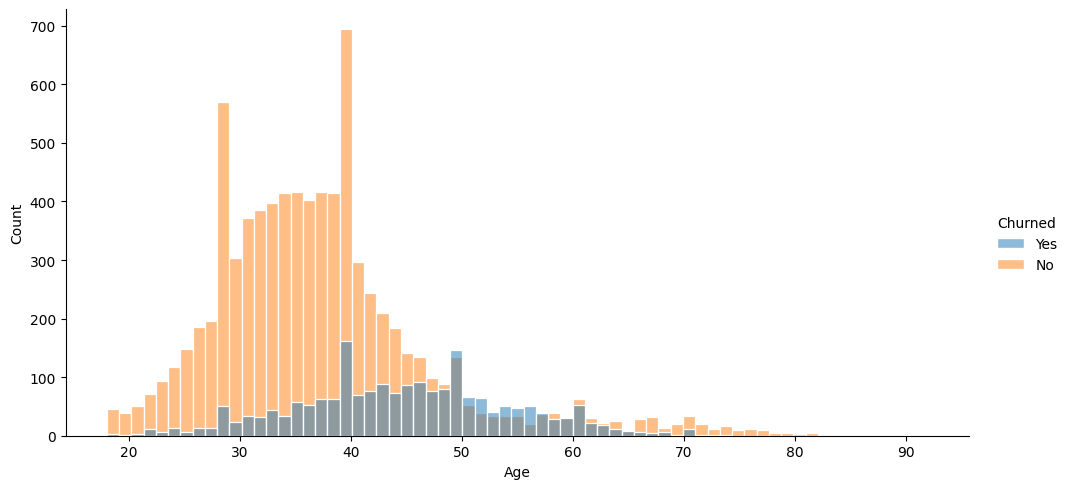

In [10]:
# plot histograms 
sns.displot(data=bank_data, x='Age', hue='Churned', edgecolor='w', aspect=2);

# Building models to predict churn

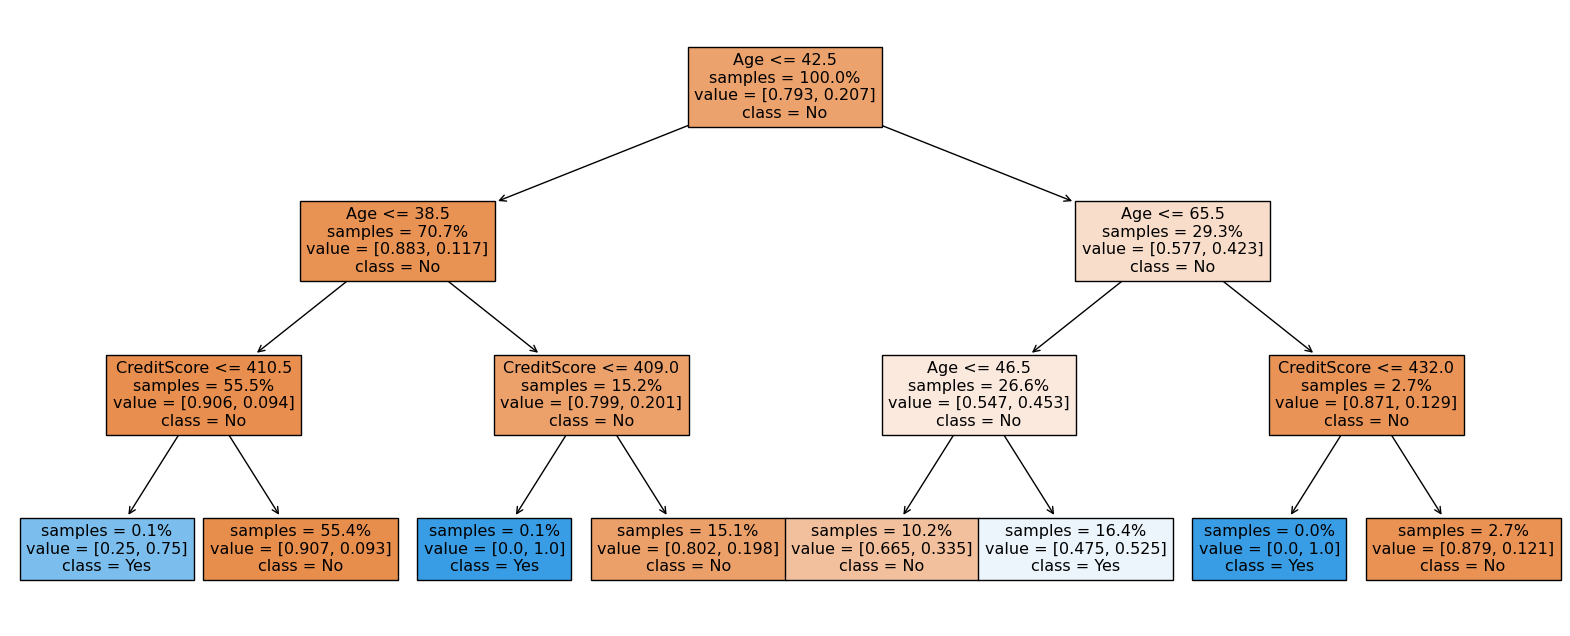

Predicted,0,1,All
Actual,,,
0,1450,167,1617
1,242,141,383
All,1692,308,2000


In [11]:
# define the input features create the input table (X) and define the target feature (y), perform the training-testing split
input_features = ['CreditScore','Age']
X = bank_data[input_features]
y = bank_data['Exited']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=2)

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
plot_decision_tree(tree_model)

# create a list of the predictions and display confusion matrix
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

note how the algorithm doesnt split first by age, then creditscore etc. it chooses each time whats best to try and get the weighted mean as close to 0 as possible. 

## Task 1
Build some more models using different combinations of input features. 

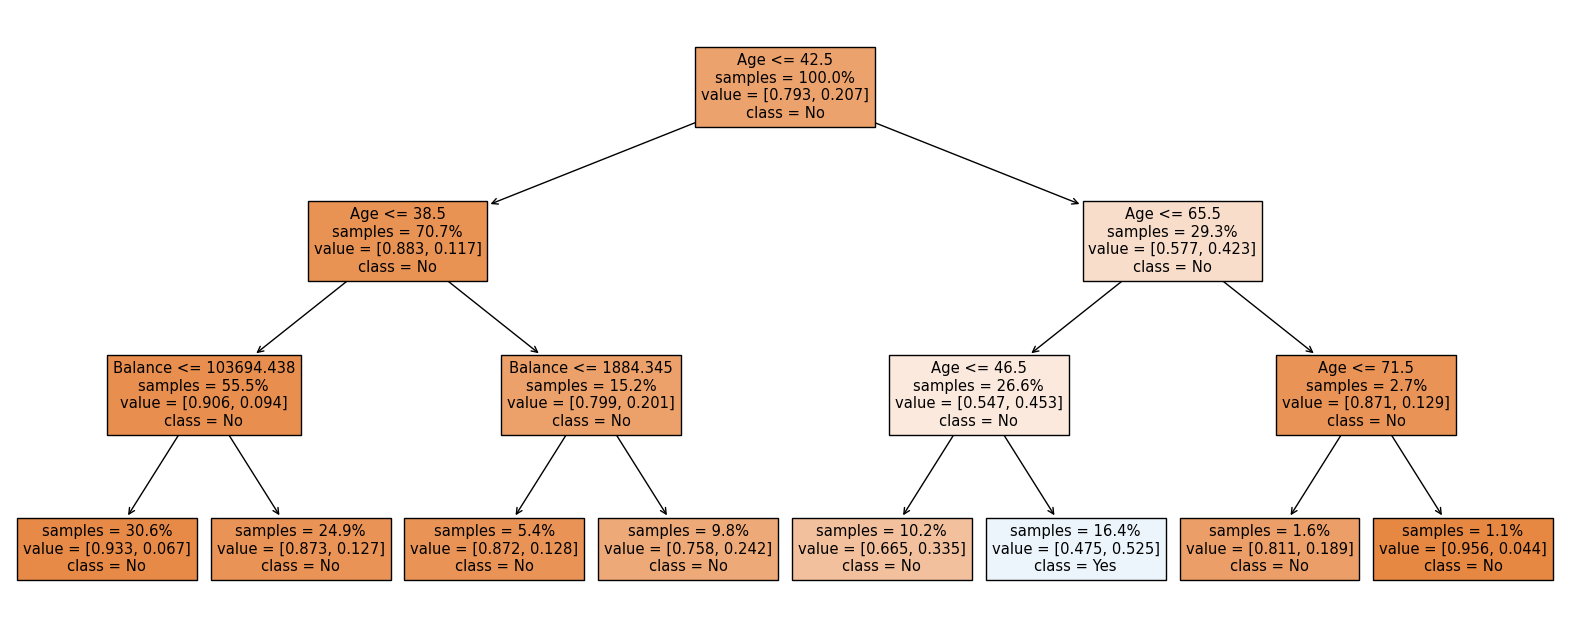

Predicted,0,1,All
Actual,,,
0,1451,166,1617
1,243,140,383
All,1694,306,2000


In [12]:
# Build a model to predict churn

input_features = ['Balance','Age']
X = bank_data[input_features]
y = bank_data['Exited']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=2)

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
plot_decision_tree(tree_model)

# create a list of the predictions and display confusion matrix
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

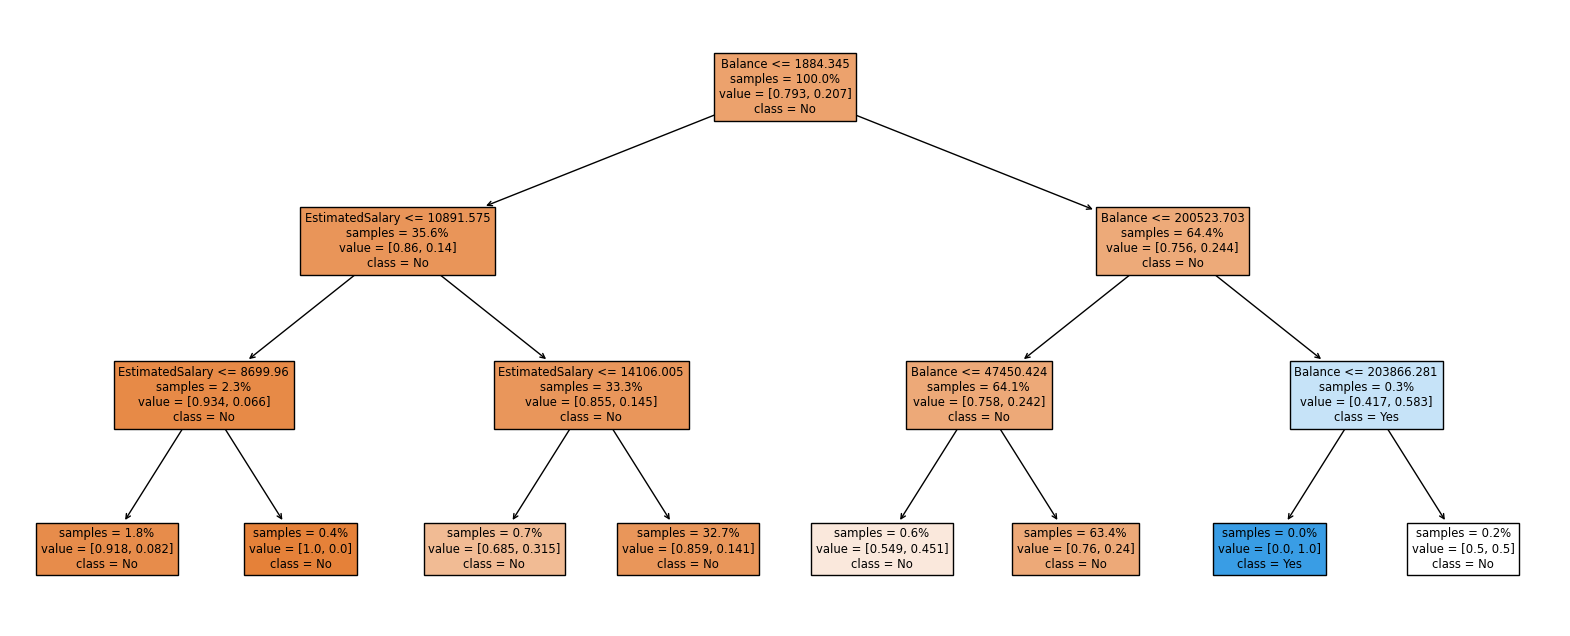

Predicted,0,1,All
Actual,,,
0,1616,1,1617
1,382,1,383
All,1998,2,2000


In [13]:
input_features = ['Balance','EstimatedSalary']
X = bank_data[input_features]
y = bank_data['Exited']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=2)

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
plot_decision_tree(tree_model)

# create a list of the predictions and display confusion matrix
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

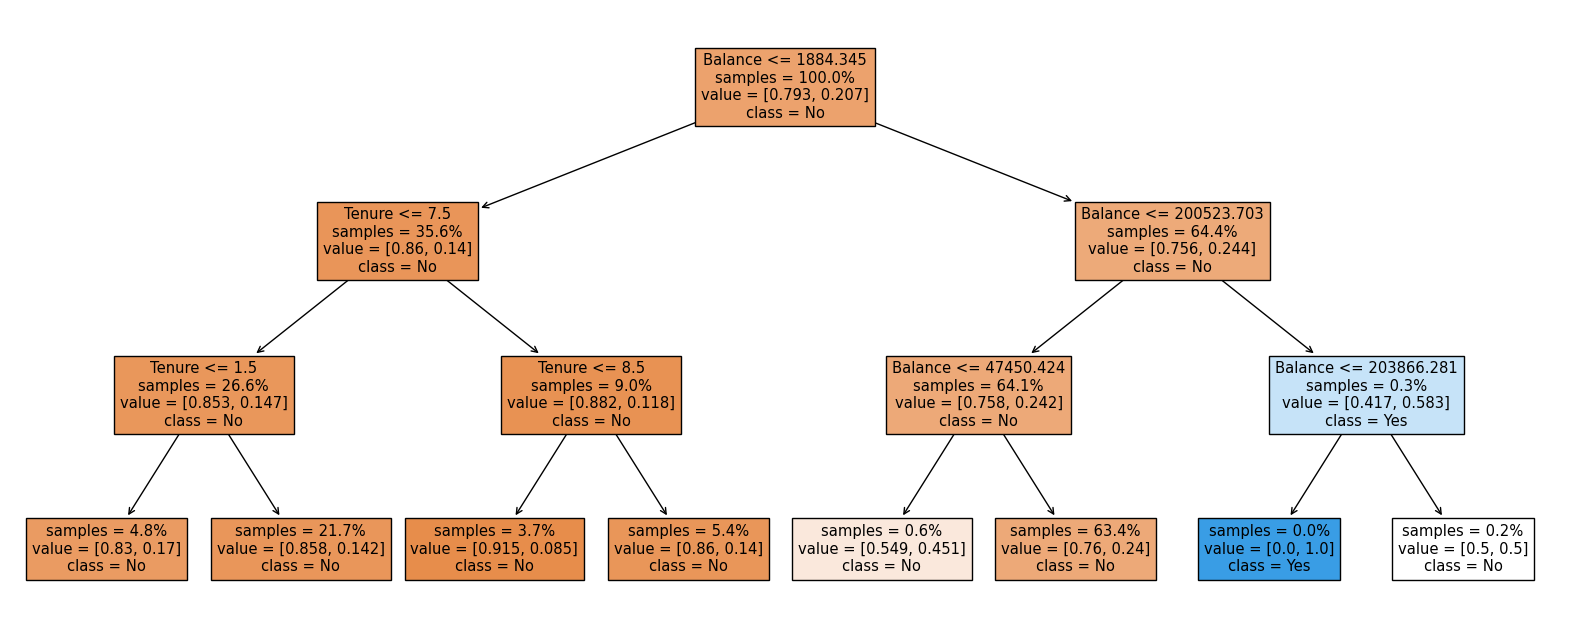

Predicted,0,1,All
Actual,,,
0,1616,1,1617
1,382,1,383
All,1998,2,2000


In [14]:
input_features = ['Balance',"Tenure"]
X = bank_data[input_features]
y = bank_data['Exited']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=2)

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
plot_decision_tree(tree_model)

# create a list of the predictions and display confusion matrix
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

the model is fairly good at identifying people who dont churn, but its really bad at predicting who will. it thinks a lot of people who do churn, wont.

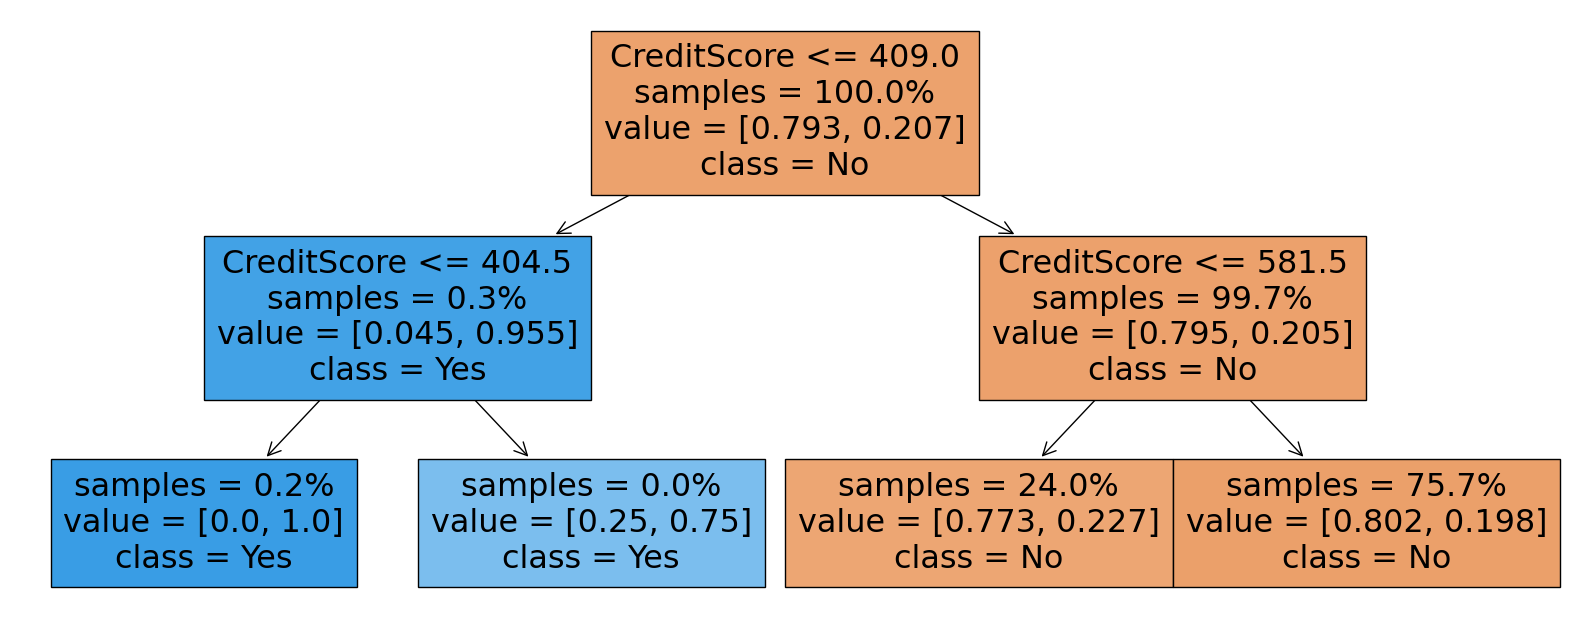

Predicted,0,1,All
Actual,,,
0,1616,1,1617
1,380,3,383
All,1996,4,2000


In [15]:
input_features = ['Tenure',"CreditScore"]
X = bank_data[input_features]
y = bank_data['Exited']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=2)

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=2).fit(X_train, y_train)
plot_decision_tree(tree_model)

# create a list of the predictions and display confusion matrix
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

## Calculating metrics for the model: precision and recall

The confusion matrix is useful information to judge the model on but finding the total number it has incorrectly identified is often too blunt a tool. In practice it is helpful to have multiple measures of how well the model has performed. These measures are known as metrics. Two of the most common metrics for classification models are precision and recall.

The model predicted 308 of the customers would churn. Of these 141 were identified correctly. This is called the **precision** and is usually given as a percentage:  
precision = 45.8%.

There were 383 customers that **actually** churned. This model correctly identified 141 of them. This is called the **recall** of the model:  
recall =  36.8%.

The code in the boxes below shows the percentage calculations.

two values can help us decide how useful a model is, using its confusion matrix:
1. precision: the proportion of values predicted as true that the model has identified. correct predicted/all predicted
2. recall: proportion of values that are really true that the model has identified.  correct predicted/all correct

think of recall as measuring false negatives and precision as measuring false positives

In [16]:
141/308

0.4577922077922078

In [17]:
141/383

0.3681462140992167

## Displaying precision and recall directly
You can display precision and recall directly for any model as shown in the code below.

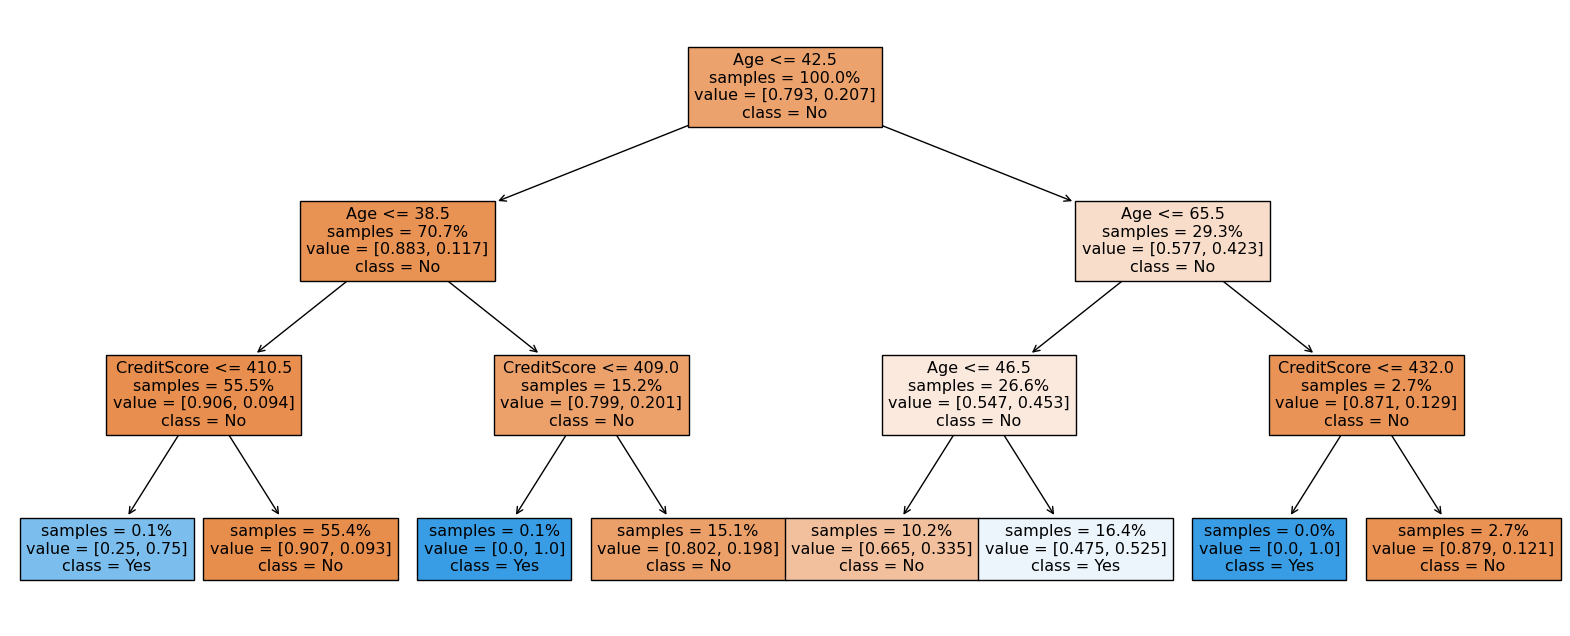

Precision:  45.8 %
Recall:  36.8 %


Predicted,0,1,All
Actual,,,
0,1450,167,1617
1,242,141,383
All,1692,308,2000


In [18]:
# define the input features create the input table (X) and define the target feature (y), perform the training-testing split
input_features = ['CreditScore','Age']
X = bank_data[input_features]
y = bank_data['Exited']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=2)

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
plot_decision_tree(tree_model)

# create a list of the predictions and display confusion matrix
y_pred = tree_model.predict(X_test)
print("Precision: ",round(100*precision_score(y_test, y_pred),1),"%")
print("Recall: ",round(100*recall_score(y_test, y_pred),1),"%")
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)


## Task 2
Create at least two more decision trees and compare
the precision and recall for these models.


Explore what happens when you create a decision
tree that doesn't create a split. (you may need to consider the confusion matrix before the precision and recall)

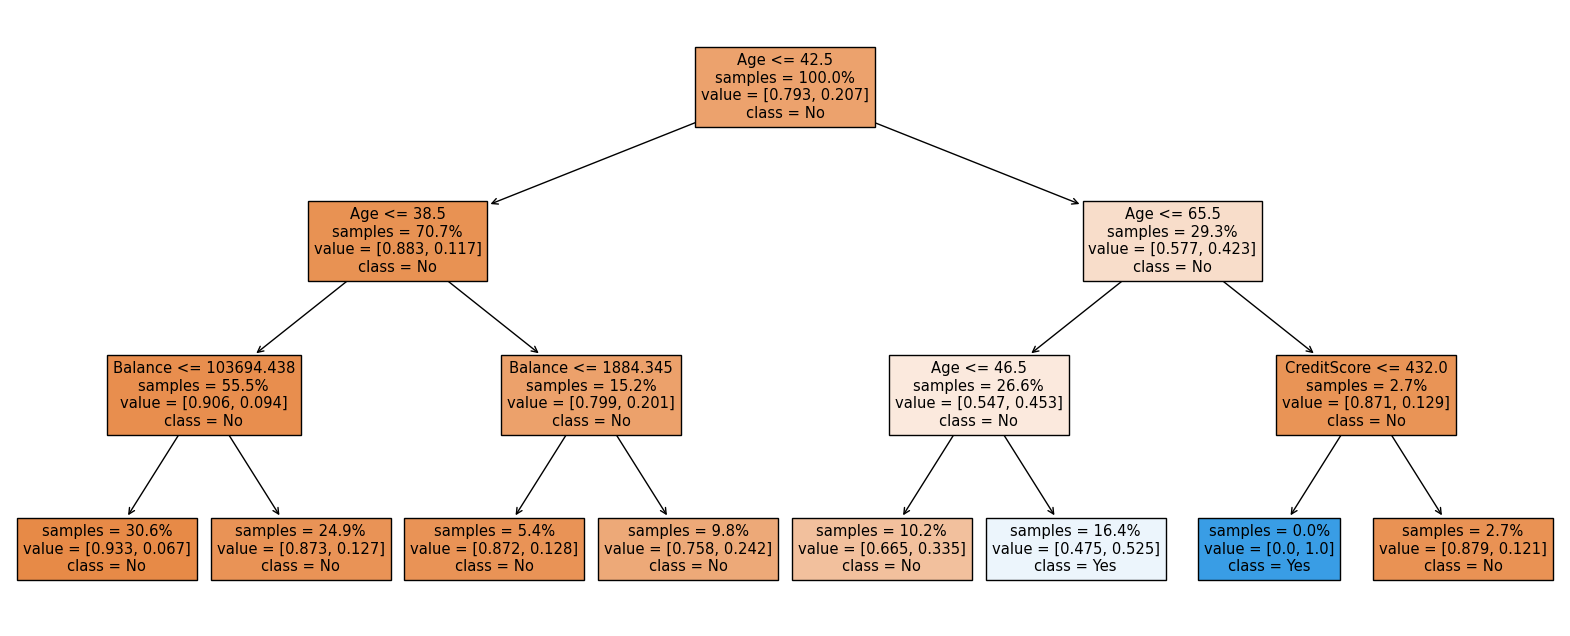

Precision:  45.8 %
Recall:  36.6 %


Predicted,0,1,All
Actual,,,
0,1451,166,1617
1,243,140,383
All,1694,306,2000


In [19]:
# define the input features create the input table (X) and define the target feature (y), perform the training-testing split
input_features = ['Balance',"CreditScore","Age"]
X = bank_data[input_features]
y = bank_data['Exited']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=2)

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
plot_decision_tree(tree_model)

# create a list of the predictions and display confusion matrix
y_pred = tree_model.predict(X_test)
print("Precision: ",round(100*precision_score(y_test, y_pred),1),"%")
print("Recall: ",round(100*recall_score(y_test, y_pred),1),"%")
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

when theres money involved, youd probably look at precision; if the bank wants to send those at risk of churning a £50 voucher, youd want a higher precision. youll loose some individuals, but youll hit a lot of people whod churn, whilst not going broke

if not, recall might be a better option. that'd hit some people not at risk of churning, but will definitely hit all of those at risk of churning

but its definitely dependent on the situation

## Overfitting

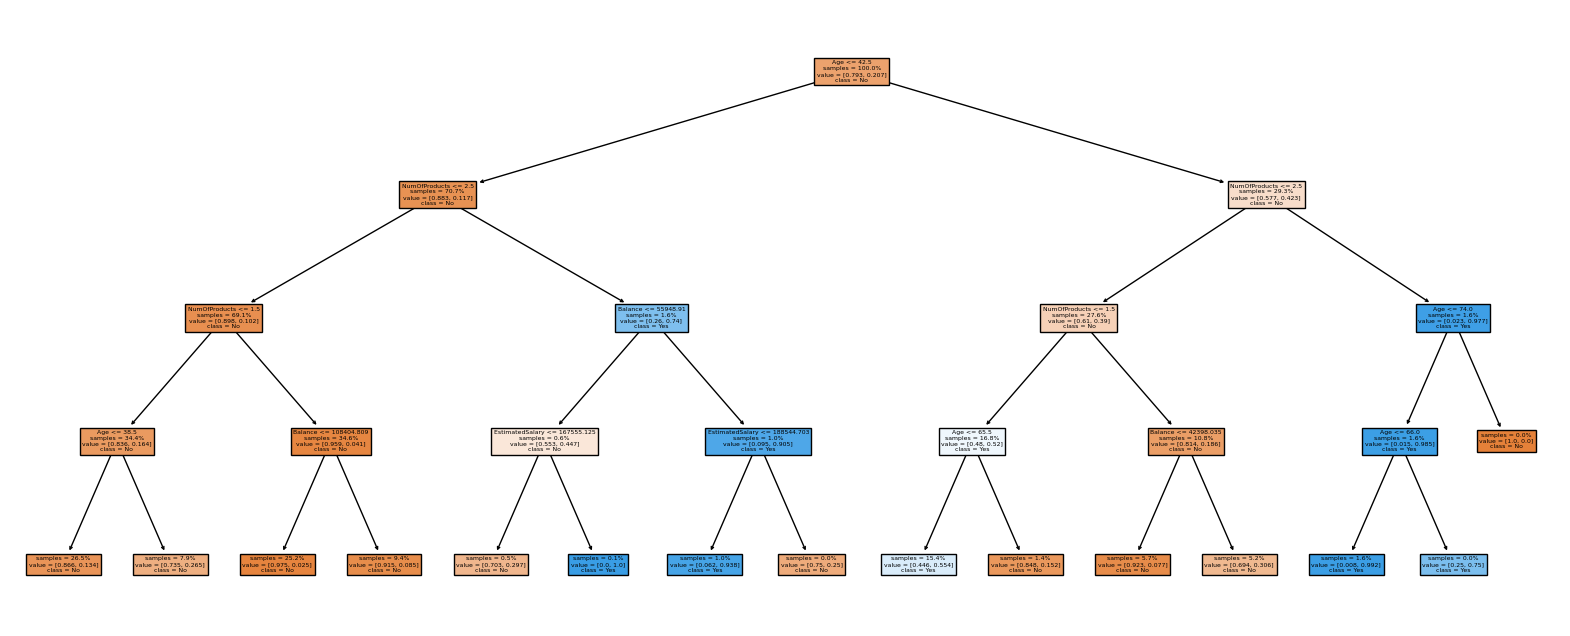

Precision:  56.9 %
Recall:  48.3 %


Predicted,0,1,All
Actual,,,
0,1477,140,1617
1,198,185,383
All,1675,325,2000


In [20]:
# high variance

# define the input features create the input table (X) and define the target feature (y), perform the training-testing split
input_features = ['CreditScore','Age','Tenure','Balance','NumOfProducts','EstimatedSalary']

X = bank_data[input_features]
y = bank_data['Exited']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=2)

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=4).fit(X_train, y_train)
plot_decision_tree(tree_model)

# create a list of the predictions and display the metrics
y_pred = tree_model.predict(X_test)
print("Precision: ",round(100*precision_score(y_test, y_pred),1),"%")
print("Recall: ",round(100*recall_score(y_test, y_pred),1),"%")
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)


plotting too many variables can also be detrimental; if you have too many, changing one wont have much of an impact, but the model geta harder to explain, and takes more time to process.  the blocks at the end might be only 1 or 2 people. this tradeoff often isnt worth it

if we only look at a few variables, that could be said to be high bias. could lead to:
- underfitting
- missing important patterns in data

if we look at too many, and have a high variance model, could lead to:
- overfitting
- might fit the training data really well
- but may perform badly on new testing data because its so rigid, so dependent on the training set.

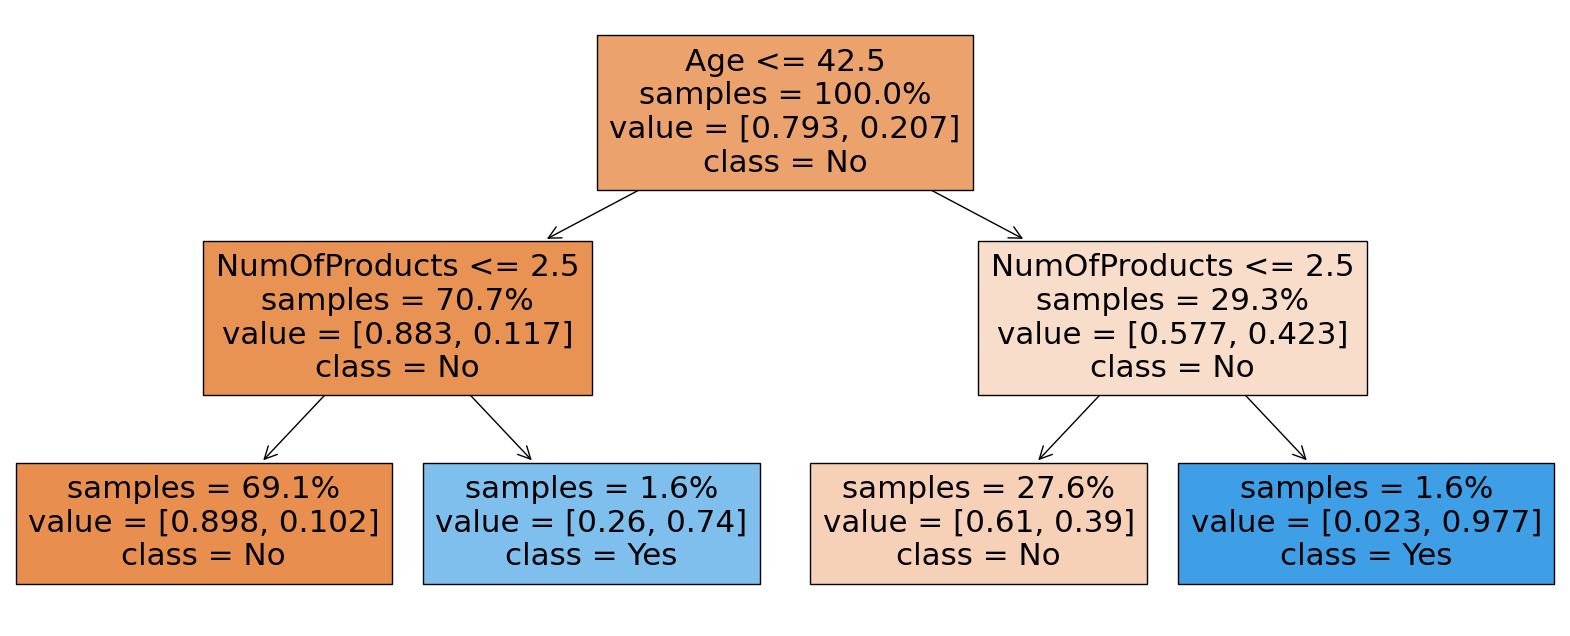

Precision:  85.7 %
Recall:  14.1 %


Predicted,0,1,All
Actual,,,
0,1608,9,1617
1,329,54,383
All,1937,63,2000


In [21]:
# high bias

# define the input features create the input table (X) and define the target feature (y), perform the training-testing split
input_features = ['CreditScore','Age','Tenure','Balance','NumOfProducts','EstimatedSalary']

X = bank_data[input_features]
y = bank_data['Exited']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=2)

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=2).fit(X_train, y_train)
plot_decision_tree(tree_model)

# create a list of the predictions and display the metrics
y_pred = tree_model.predict(X_test)
print("Precision: ",round(100*precision_score(y_test, y_pred),1),"%")
print("Recall: ",round(100*recall_score(y_test, y_pred),1),"%")
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)